# Baselines evaluation

This notebook is the starting point for testing and evaluating the baselines on the timestamped feature table built in [03_feature_engineering.ipynb](/notebooks/03_feature_engineering.ipynb). It loads the same three Nginx log sources, builds `features_df`, applies explicit baselines.

# Setup and input data

In [2]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from IPython.display import display

project_root = Path.cwd().parent 
sys.path.append(str(project_root))
import importlib
import src.fink_api_anomaly_detection.baselines as baselines
importlib.reload(baselines)

from src.fink_api_anomaly_detection.baselines import (
    ClassicalZScoreBaseline,
    ConditionalTemporalBaseline,
    OperationalThresholdBaseline,
    OperationalThresholds,
    RobustZScoreBaseline,
    report_evaluation_metrics,
)
from src.fink_api_anomaly_detection.data.raw_logs import ls_log_files
from src.fink_api_anomaly_detection.preprocess.nginx_logs.access_logs import build_access_dataframe
from src.fink_api_anomaly_detection.preprocess.nginx_logs.error_logs import build_error_dataframe
from src.fink_api_anomaly_detection.preprocess.nginx_logs.geo_logs import build_geo_dataframe
from src.fink_api_anomaly_detection.features.nginx_logs import build_temporal_features


DATA_DIR = project_root / "data" / "nginx_history_logs"
print(f"Dataset directory: {DATA_DIR.resolve()}")

Dataset directory: /home/machter-l/fink-api-forecasting-anomaly-detection/data/nginx_history_logs


Listing of available logs files (per category):

In [3]:
access_files = ls_log_files(DATA_DIR, "access-logs")
geo_files = ls_log_files(DATA_DIR, "geo-logs")
error_files = ls_log_files(DATA_DIR, "error-logs")


Parsing the raw logs into Dataframes can take a few minutes. 

In [4]:
access_df = build_access_dataframe(access_files)
geo_df = build_geo_dataframe(geo_files)
errors_df = build_error_dataframe(error_files)

print(f"access_df.shape: {access_df.shape}")
print(f"geo_df.shape: {geo_df.shape}")
print(f"errors_df.shape: {errors_df.shape}")

access_df.shape: (1005103, 16)
geo_df.shape: (1005103, 6)
errors_df.shape: (833, 17)


The next cell follows notebook 03 and builds one row per  each 5-minute window : 

In [5]:
features_df = build_temporal_features(access_df, geo_df, errors_df)

print(f"Feature table shape: {features_df.shape}")
print(f"Time span: {features_df['timestamp'].min()} to {features_df['timestamp'].max()}")
display(features_df.head())
display(features_df.tail())

Feature table shape: (4033, 24)
Time span: 2026-10-03 00:00:00+00:00 to 2026-10-17 00:00:00+00:00


,timestamp,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,...,nginx_broken_pipe_count,unique_country_count,top_country_share,top_country_share_without_france,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,request_count_delta,http_5xx_rate_delta,nginx_error_count_delta
0,2026-10-03 00:00:00+00:00,30,1,29,0,2,0.0,0.066667,6,1197413,...,0,3,0.600000,0,30,0,4,0.0,0.0,0.0
1,2026-10-03 00:05:00+00:00,36,0,36,0,0,0.0,0.0,4,3077416,...,0,3,0.472222,0,36,0,4,6.0,-0.066667,0.0
2,2026-10-03 00:10:00+00:00,353,1,352,0,0,0.0,0.0,9,83959825,...,0,4,0.929178,0,353,0,4,317.0,0.0,0.0
3,2026-10-03 00:15:00+00:00,363,1,362,0,0,0.0,0.0,9,100850864,...,0,4,0.851240,0,363,0,5,10.0,0.0,0.0
4,2026-10-03 00:20:00+00:00,327,2,325,1,4,0.003058,0.012232,8,72522424,...,1,3,0.935583,0,326,1,5,-36.0,0.012232,2.0


,timestamp,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,...,nginx_broken_pipe_count,unique_country_count,top_country_share,top_country_share_without_france,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,request_count_delta,http_5xx_rate_delta,nginx_error_count_delta
4028,2026-10-16 23:40:00+00:00,44,2,42,0,0,0.0,0.0,10,608838,...,0,3,0.772727,0,44,0,6,3.0,0.0,0.0
4029,2026-10-16 23:45:00+00:00,79,4,75,0,0,0.0,0.0,8,1021306,...,0,4,0.772152,0,76,3,9,35.0,0.0,0.0
4030,2026-10-16 23:50:00+00:00,71,4,67,0,2,0.0,0.028169,10,371111,...,0,3,0.563380,0,71,0,10,-8.0,0.028169,1.0
4031,2026-10-16 23:55:00+00:00,67,4,63,0,0,0.0,0.0,10,1450850,...,0,4,0.462687,0,67,0,7,-4.0,-0.028169,-1.0
4032,2026-10-17 00:00:00+00:00,6,0,6,0,0,0.0,0.0,1,42405,...,0,1,1.000000,0,6,0,1,-61.0,0.0,0.0


# Baselines evaluation

In [13]:
df = features_df.iloc[:-1].copy()

## B1 : Operational threshold rules for anomaly detection

**Baseline 1** flags high 5xx/4xx rates, unusually high request volume, and high Nginx error counts. The score is the number of rules triggered in a window; any positive score (>0) is an anomaly.

Each upper threshold is computed from the first half of the chronological data (days 1-7) as **mean + 3 population standard deviations**. Rate thresholds are capped at 1.0, their maximum possible value.

In [14]:
b1_reference_df = df.iloc[: int(len(df) * 0.5)].copy()
b1_evaluation_df = df.iloc[int(len(df) * 0.5):].copy()
sigma_multiplier = 3.0

def mean_plus_sigma(feature):
    values = b1_reference_df[feature]
    return float(values.mean() + sigma_multiplier * values.std(ddof=0))

threshold_values = {
    "http_5xx_rate_max": min(1.0, mean_plus_sigma("http_5xx_rate")),
    "http_4xx_rate_max": min(1.0, mean_plus_sigma("http_4xx_rate")),
    "request_count_max": mean_plus_sigma("request_count"),
    "nginx_error_count_max": mean_plus_sigma("nginx_error_count"),
}
thresholds = OperationalThresholds(**threshold_values)
baseline = OperationalThresholdBaseline(thresholds)

display(pd.DataFrame([threshold_values], index=[f"mean + {sigma_multiplier:g} sigma"]))

,http_5xx_rate_max,http_4xx_rate_max,request_count_max,nginx_error_count_max
mean + 3 sigma,0.156893,0.216667,1340.094372,2.086423


Notebook 03 notes that the current dataset's final five-minute window is partial. Exclude it from this first evaluation so its low request count does not create an artificial alert. Recheck this assumption when the dataset changes.

In [15]:
predictions_df = baseline.predict(b1_evaluation_df)

print(f"B1 - Evaluated windows: {len(predictions_df)}")
print(f"B1 - Flagged windows: {int(predictions_df['is_anomaly'].sum())}")
print(f"B1 - Flagged percentage: {predictions_df['is_anomaly'].mean():.2%}")
display(predictions_df.head())
display(predictions_df.loc[predictions_df["is_anomaly"]].head(20))

B1 - Evaluated windows: 2016
B1 - Flagged windows: 82
B1 - Flagged percentage: 4.07%


,timestamp,anomaly_score,is_anomaly
0,2026-10-10 00:00:00+00:00,0.0,False
1,2026-10-10 00:05:00+00:00,0.0,False
2,2026-10-10 00:10:00+00:00,0.0,False
3,2026-10-10 00:15:00+00:00,0.0,False
4,2026-10-10 00:20:00+00:00,0.0,False


,timestamp,anomaly_score,is_anomaly
5,2026-10-10 00:25:00+00:00,1.0,True
22,2026-10-10 01:50:00+00:00,1.0,True
23,2026-10-10 01:55:00+00:00,1.0,True
161,2026-10-10 13:25:00+00:00,1.0,True
169,2026-10-10 14:05:00+00:00,1.0,True
198,2026-10-10 16:30:00+00:00,1.0,True
204,2026-10-10 17:00:00+00:00,1.0,True
277,2026-10-10 23:05:00+00:00,1.0,True
278,2026-10-10 23:10:00+00:00,1.0,True
279,2026-10-10 23:15:00+00:00,1.0,True



Inspect the rules and flagged windows : Join predictions back to the features to see which observations triggered alerts. This is an initial qualitative check, not a precision/recall evaluation( the dataset has no confirmed anomaly labels).

In [16]:
results_df = df.merge(predictions_df,on="timestamp",how="inner",validate="one_to_one")

display(
    results_df.loc[results_df["is_anomaly"],["timestamp","anomaly_score","request_count","http_5xx_rate", "http_4xx_rate","nginx_error_count"],]
    .sort_values("anomaly_score", ascending=False)
)

,timestamp,anomaly_score,request_count,http_5xx_rate,http_4xx_rate,nginx_error_count
1879,2026-10-16 12:35:00+00:00,3.0,3091,0.000971,0.925914,3
982,2026-10-13 09:50:00+00:00,3.0,141,0.368794,0.234043,3
1875,2026-10-16 12:15:00+00:00,3.0,5947,0.000841,0.559442,5
1877,2026-10-16 12:25:00+00:00,3.0,10273,0.000292,0.81758,25
1873,2026-10-16 12:05:00+00:00,3.0,6536,0.001683,0.979651,15
...,...,...,...,...,...,...
1750,2026-10-16 01:50:00+00:00,1.0,586,0.290102,0.0,0
1710,2026-10-15 22:30:00+00:00,1.0,168,0.005952,0.285714,1
1716,2026-10-15 23:00:00+00:00,1.0,191,0.020942,0.670157,0
1874,2026-10-16 12:10:00+00:00,1.0,7559,0.000132,0.083477,1


## B2: Classical Z-score

B2 evaluates a selected subset of features independently: `request_count`, `http_5xx_count`, `http_5xx_rate`, `http_4xx_count`, `http_4xx_rate`, and `nginx_error_count`. Although this method could be applied to all 23 numerical features, we limit it to these six features.

The absolute Z-score is calculated using the mean and population standard deviation of a reference period. Values with an absolute Z-score strictly greater than 3 (`|z-score| > 3`) are flagged as anomalies.

**Temporal split (not random):** The first **50% of the chronological windows (days 1-7)** form the reference period, and the **last 50% (days 8-14)** form the evaluation period. Statistics are calculated exclusively on the reference period and then applied to the evaluation period.

In [17]:
split_index = int(len(df) * 0.5)
b2_reference_df = df.iloc[:split_index].copy()
b2_evaluation_df = df.iloc[split_index:].copy()

print(f"B2 - Reference windows: {len(b2_reference_df)} = {len(b2_reference_df)/len(df):.2%} %")
print(f"B2 - Evaluation windows: {len(b2_evaluation_df)} = {len(b2_evaluation_df)/len(df):.2%} %")

B2 - Reference windows: 2016 = 50.00% %
B2 - Evaluation windows: 2016 = 50.00% %


In [18]:
b2_features = ["request_count","http_5xx_count","http_5xx_rate","http_4xx_count","http_4xx_rate","nginx_error_count"]
b2_predictions = {}
b2_summary = []

for feature in b2_features:
    baseline = ClassicalZScoreBaseline(feature=feature, threshold=3.0)
    baseline.fit(b2_reference_df)
    predictions = baseline.predict(b2_evaluation_df)
    b2_predictions[feature] = predictions
    b2_summary.append(
        {
            "feature": feature,
            "evaluated_windows": len(predictions),
            "flagged_windows": int(predictions["is_anomaly"].sum()),
            "flagged_percentage": predictions["is_anomaly"].mean(),
        }
    )

b2_summary_df = pd.DataFrame(b2_summary)
display(b2_summary_df)

,feature,evaluated_windows,flagged_windows,flagged_percentage
0,request_count,2016,7,0.003472
1,http_5xx_count,2016,24,0.011905
2,http_5xx_rate,2016,42,0.020833
3,http_4xx_count,2016,41,0.020337
4,http_4xx_rate,2016,41,0.020337
5,nginx_error_count,2016,8,0.003968


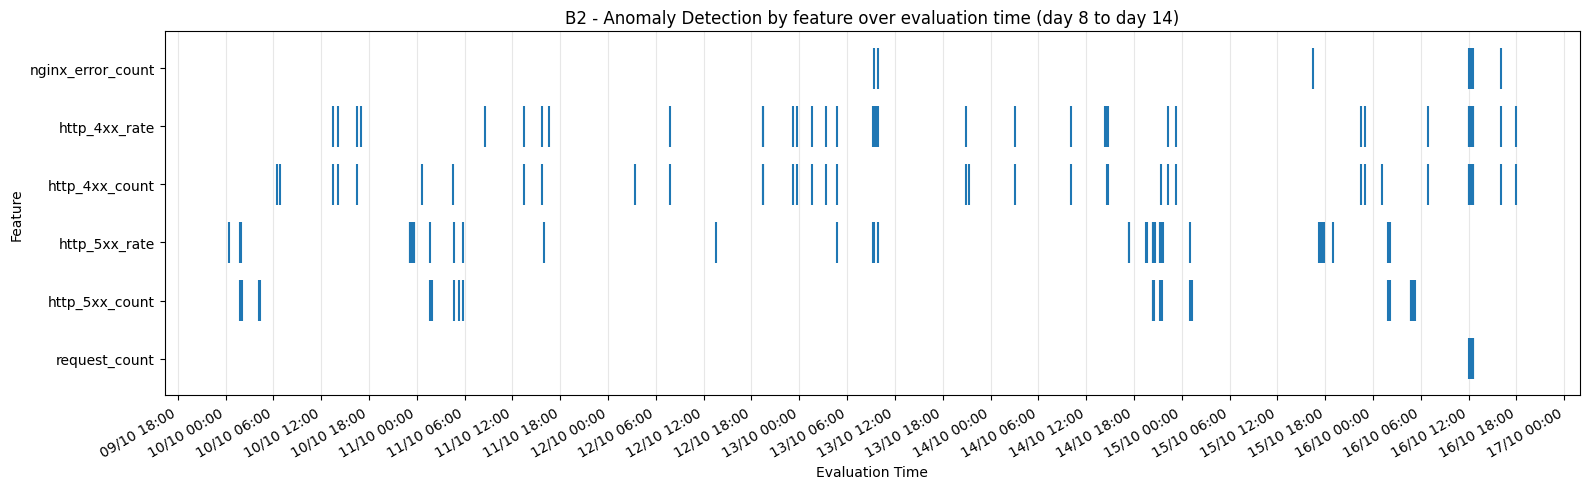

In [19]:
flag_matrix = pd.DataFrame(
    {
        feature: predictions["is_anomaly"].to_numpy()
        for feature, predictions in b2_predictions.items()
    },
    index=pd.to_datetime(b2_evaluation_df["timestamp"]),
)

fig, ax = plt.subplots(figsize=(16, 5))

for y, feature in enumerate(flag_matrix.columns):
    flagged_times = flag_matrix.index[flag_matrix[feature]]
    ax.vlines(flagged_times, y - 0.35, y + 0.35, linewidth=1.5)

ax.set_yticks(range(len(flag_matrix.columns)))
ax.set_yticklabels(flag_matrix.columns)
ax.set_title("B2 - Anomaly Detection by feature over evaluation time (day 8 to day 14)")
ax.set_xlabel("Evaluation Time")
ax.set_ylabel("Feature")

ax.xaxis.set_major_locator(mdates.HourLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %H:%M"))

ax.grid(axis="x", alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [20]:
flagged_by_any_feature = flag_matrix.any(axis=1)
n_flagged_windows = int(flagged_by_any_feature.sum())

print(
    f"Windows flagged by at least one feature: "
    f"{n_flagged_windows} / {len(flag_matrix)} "
    f"({n_flagged_windows / len(flag_matrix):.2%})"
)

Windows flagged by at least one feature: 101 / 2016 (5.01%)


**B2 conclusion**: Compared with B1, the classical Z-score produces a much smaller alert volume. Over 2016 evaluation windows, it flags 7 windows for `request_count` (0.35%), 24 for `http_5xx_count` (1.19%), 42 for `http_5xx_rate` (2.08%), 41 for each of `http_4xx_count` and `http_4xx_rate` (2.03%), and 8 for `nginx_error_count` (0.40%). The absence of labelled incidents means we cannot determine whether these alerts are genuine incidents or false positives. Results also depend on the reference period: unusual values in the first half can affect the mean and standard deviation used to score the second half.

## B3: Robust Z-score (median and MAD)

B3 evaluates the same six indicators as B2 independently, using the same chronological 50/50 reference/evaluation split. It replaces the mean and standard deviation with the reference median and median absolute deviation (MAD). The robust score is `abs(0.6745 * (value - median) / MAD)`; scores strictly greater than 3.5 are flagged. When the reference MAD is zero, values different from the reference median are flagged without generating an infinite score.

In [21]:
b3_features = b2_features.copy()
b3_predictions = {}
b3_summary = []

for feature in b3_features:
    baseline = RobustZScoreBaseline(feature=feature, threshold=3.5)
    baseline.fit(b2_reference_df)
    predictions = baseline.predict(b2_evaluation_df)
    b3_predictions[feature] = predictions
    b3_summary.append(
        {
            "feature": feature,
            "evaluated_windows": len(predictions),
            "flagged_windows": int(predictions["is_anomaly"].sum()),
            "flagged_percentage": predictions["is_anomaly"].mean(),
        }
    )

b3_summary_df = pd.DataFrame(b3_summary)
display(b3_summary_df)

,feature,evaluated_windows,flagged_windows,flagged_percentage
0,request_count,2016,23,0.011409
1,http_5xx_count,2016,113,0.056052
2,http_5xx_rate,2016,309,0.153274
3,http_4xx_count,2016,455,0.225694
4,http_4xx_rate,2016,455,0.225694
5,nginx_error_count,2016,227,0.112599


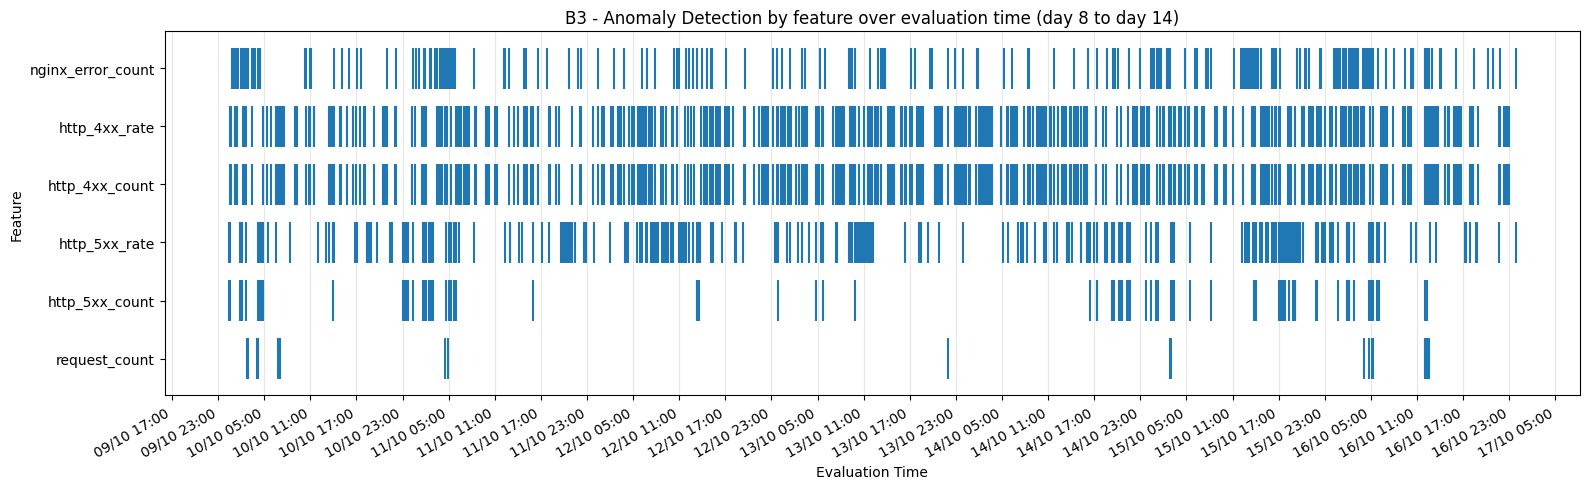

In [22]:
import matplotlib.dates as mdates

b3_flag_matrix = pd.DataFrame(
    {
        feature: predictions["is_anomaly"].to_numpy()
        for feature, predictions in b3_predictions.items()
    },
    index=pd.to_datetime(b2_evaluation_df["timestamp"]),
)

fig, ax = plt.subplots(figsize=(16, 5))
for y, feature in enumerate(b3_flag_matrix.columns):
    flagged_times = b3_flag_matrix.index[b3_flag_matrix[feature]]
    ax.vlines(flagged_times, y - 0.35, y + 0.35, linewidth=1.5)

ax.set_yticks(range(len(b3_flag_matrix.columns)))
ax.set_yticklabels(b3_flag_matrix.columns)
ax.set_title("B3 - Anomaly Detection by feature over evaluation time (day 8 to day 14)")
ax.set_xlabel("Evaluation Time")
ax.set_ylabel("Feature")
ax.xaxis.set_major_locator(mdates.HourLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %H:%M"))
ax.grid(axis="x", alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [23]:
flagged_by_any_feature = b3_flag_matrix.any(axis=1)
n_flagged_windows = int(flagged_by_any_feature.sum())

print(
    f"Windows flagged by at least one feature: "
    f"{n_flagged_windows} / {len(b3_flag_matrix)} "
    f"({n_flagged_windows / len(b3_flag_matrix):.2%})"
)

Windows flagged by at least one feature: 817 / 2016 (40.53%)


In [24]:
b2_b3_comparison_df = b2_summary_df[["feature", "flagged_windows",]].merge(
    b3_summary_df[["feature", "flagged_windows", ]],
    on="feature",
    suffixes=("_b2", "_b3"),
    validate="one_to_one",
)
display(b2_b3_comparison_df)

,feature,flagged_windows_b2,flagged_windows_b3
0,request_count,7,23
1,http_5xx_count,24,113
2,http_5xx_rate,42,309
3,http_4xx_count,41,455
4,http_4xx_rate,41,455
5,nginx_error_count,8,227


**Conclusion B3:** B3 detects significantly more anomalous windows (flagged by at least one feature) than B2 - 817 out of 2016 (40.53%) compared to 101 (5.01%). This disparity is particularly pronounced for **`http_4xx_count`, `http_4xx_rate`, and `http_5xx_rate`**. This suggests that the robust Z-score—based on the median and the MAD—is more sensitive to deviations from the typical behavior of these metrics. However, this increased sensitivity does not necessarily guarantee better detection; the flagged windows must be examined to distinguish between meaningful anomalies and normal traffic variations.

## B4: Conditional temporal reference

B4 compares each observation with its own (here 30-minute - modifiable) time-of-day context in UTC. For every feature, the contextual median and MAD are calculated from the first 50% of chronological windows, pooling the corresponding time slots across reference days without separating weekdays. The robust score is `abs(value - contextual_median) / (1.4826 * contextual_MAD)`; scores strictly greater than 3.5 are flagged. If a context has zero MAD, deviations from its median are flagged without producing infinite scores. The same six features and evaluation period as B2 and B3 are used.

In [25]:
b4_features = b2_features.copy()
b4_predictions = {}
b4_summary = []

for feature in b4_features:
    baseline = ConditionalTemporalBaseline(
        feature=feature,
        threshold=3.5,
        context_minutes=30,
    )
    baseline.fit(b2_reference_df)
    predictions = baseline.predict(b2_evaluation_df)
    b4_predictions[feature] = predictions
    b4_summary.append(
        {
            "feature": feature,
            "evaluated_windows": len(predictions),
            "flagged_windows": int(predictions["is_anomaly"].sum()),
            "flagged_percentage": predictions["is_anomaly"].mean(),
        }
    )

b4_summary_df = pd.DataFrame(b4_summary)
display(b4_summary_df)

,feature,evaluated_windows,flagged_windows,flagged_percentage
0,request_count,2016,290,0.143849
1,http_5xx_count,2016,300,0.148810
2,http_5xx_rate,2016,390,0.193452
3,http_4xx_count,2016,455,0.225694
4,http_4xx_rate,2016,455,0.225694
5,nginx_error_count,2016,227,0.112599


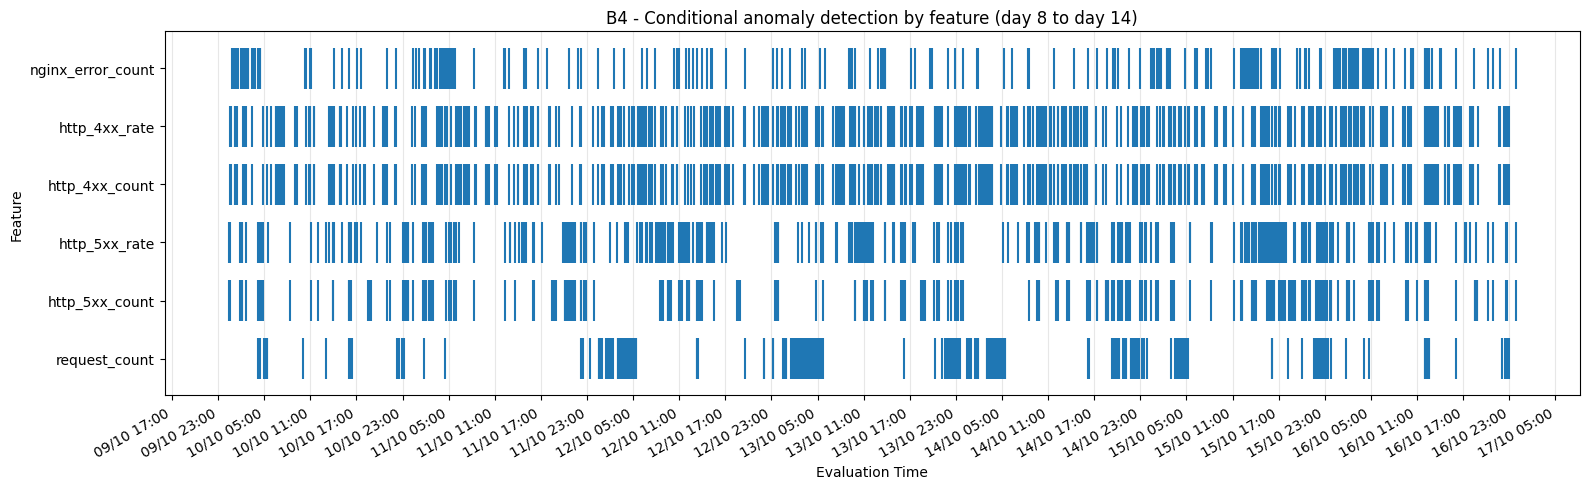

In [26]:
b4_flag_matrix = pd.DataFrame(
    {
        feature: predictions["is_anomaly"].to_numpy()
        for feature, predictions in b4_predictions.items()
    },
    index=pd.to_datetime(b2_evaluation_df["timestamp"]),
)

fig, ax = plt.subplots(figsize=(16, 5))
for y, feature in enumerate(b4_flag_matrix.columns):
    flagged_times = b4_flag_matrix.index[b4_flag_matrix[feature]]
    ax.vlines(flagged_times, y - 0.35, y + 0.35, linewidth=1.5)

ax.set_yticks(range(len(b4_flag_matrix.columns)))
ax.set_yticklabels(b4_flag_matrix.columns)
ax.set_title("B4 - Conditional anomaly detection by feature (day 8 to day 14)")
ax.set_xlabel("Evaluation Time")
ax.set_ylabel("Feature")
ax.xaxis.set_major_locator(mdates.HourLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %H:%M"))
ax.grid(axis="x", alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [27]:
b2_b3_b4_comparison_df = (
    b2_summary_df[["feature", "flagged_windows"]]
    .merge(
        b3_summary_df[["feature", "flagged_windows"]],
        on="feature",
        suffixes=("_b2", "_b3"),
        validate="one_to_one",
    )
    .merge(
        b4_summary_df[["feature", "flagged_windows"]],
        on="feature",
        validate="one_to_one",
    )
    .rename(columns={"flagged_windows": "flagged_windows_b4"})
)
display(b2_b3_b4_comparison_df)

b4_any_feature_alerts = b4_flag_matrix.any(axis=1)
print(
    f"B4 - Windows flagged by at least one feature: "
    f"{int(b4_any_feature_alerts.sum())} / {len(b4_any_feature_alerts)} "
    f"({b4_any_feature_alerts.mean():.2%})"
)

,feature,flagged_windows_b2,flagged_windows_b3,flagged_windows_b4
0,request_count,7,23,290
1,http_5xx_count,24,113,300
2,http_5xx_rate,42,309,390
3,http_4xx_count,41,455,455
4,http_4xx_rate,41,455,455
5,nginx_error_count,8,227,227


B4 - Windows flagged by at least one feature: 1041 / 2016 (51.64%)


## Comparative : B2, B3 and B4

The three baselines were evaluated on the same **2016 windows** (evaluation data -- the second half of the time series), using 6 indicators (features) scored independently.

| Baseline | Windows flagged by at least one indicator | Alert rate |
|---|---:|---:|
| **B2 - Classical Z-score** | 101 / 2016 | 5.01% |
| **B3 - Robust Z-score (median/MAD)** | 817 / 2016 | 40.53% |
| **B4 - Conditional temporal reference (30-minute slots)** | 1041 / 2016 | 51.64% |

- **B2 is the most conservative**: it raises relatively few alerts. Its mean and standard deviation are, however sensitive to extreme observations in the reference period.
- **B3 raises substantially more alerts than B2**, especially for `http_4xx_count` and `http_4xx_rate` (455 windows each), and `http_5xx_rate` (309). The median/MAD reduce the influence of extreme reference values, but the higher alert rate does not establish better detection.
- **B4 raises the most alerts overall** (51.64%). The counts are especially high for `http_4xx_count` and `http_4xx_rate` (455 each), `http_5xx_rate` (390), and `request_count` (290). Although B4 accounts for time-of-day patterns, this result shows that the current 30-minute contextual reference and threshold still flag many windows; it does not by itself demonstrate improved handling of daily cycles.

Since the dataset has no labelled incidents, we cannot determine which alerts are true anomalies or compare the methods real detection accuracy. **For now, B2 produces the most manageable alert volume, while B3 and B4 are more sensitive but require further review and calibration.**

## Request volume over time by baseline

These four panels show the evaluation-period request count over time. Windows flagged as anomalous by each baseline are highlighted in red; for B2-B4, a window is highlighted when at least one feature is flagged.

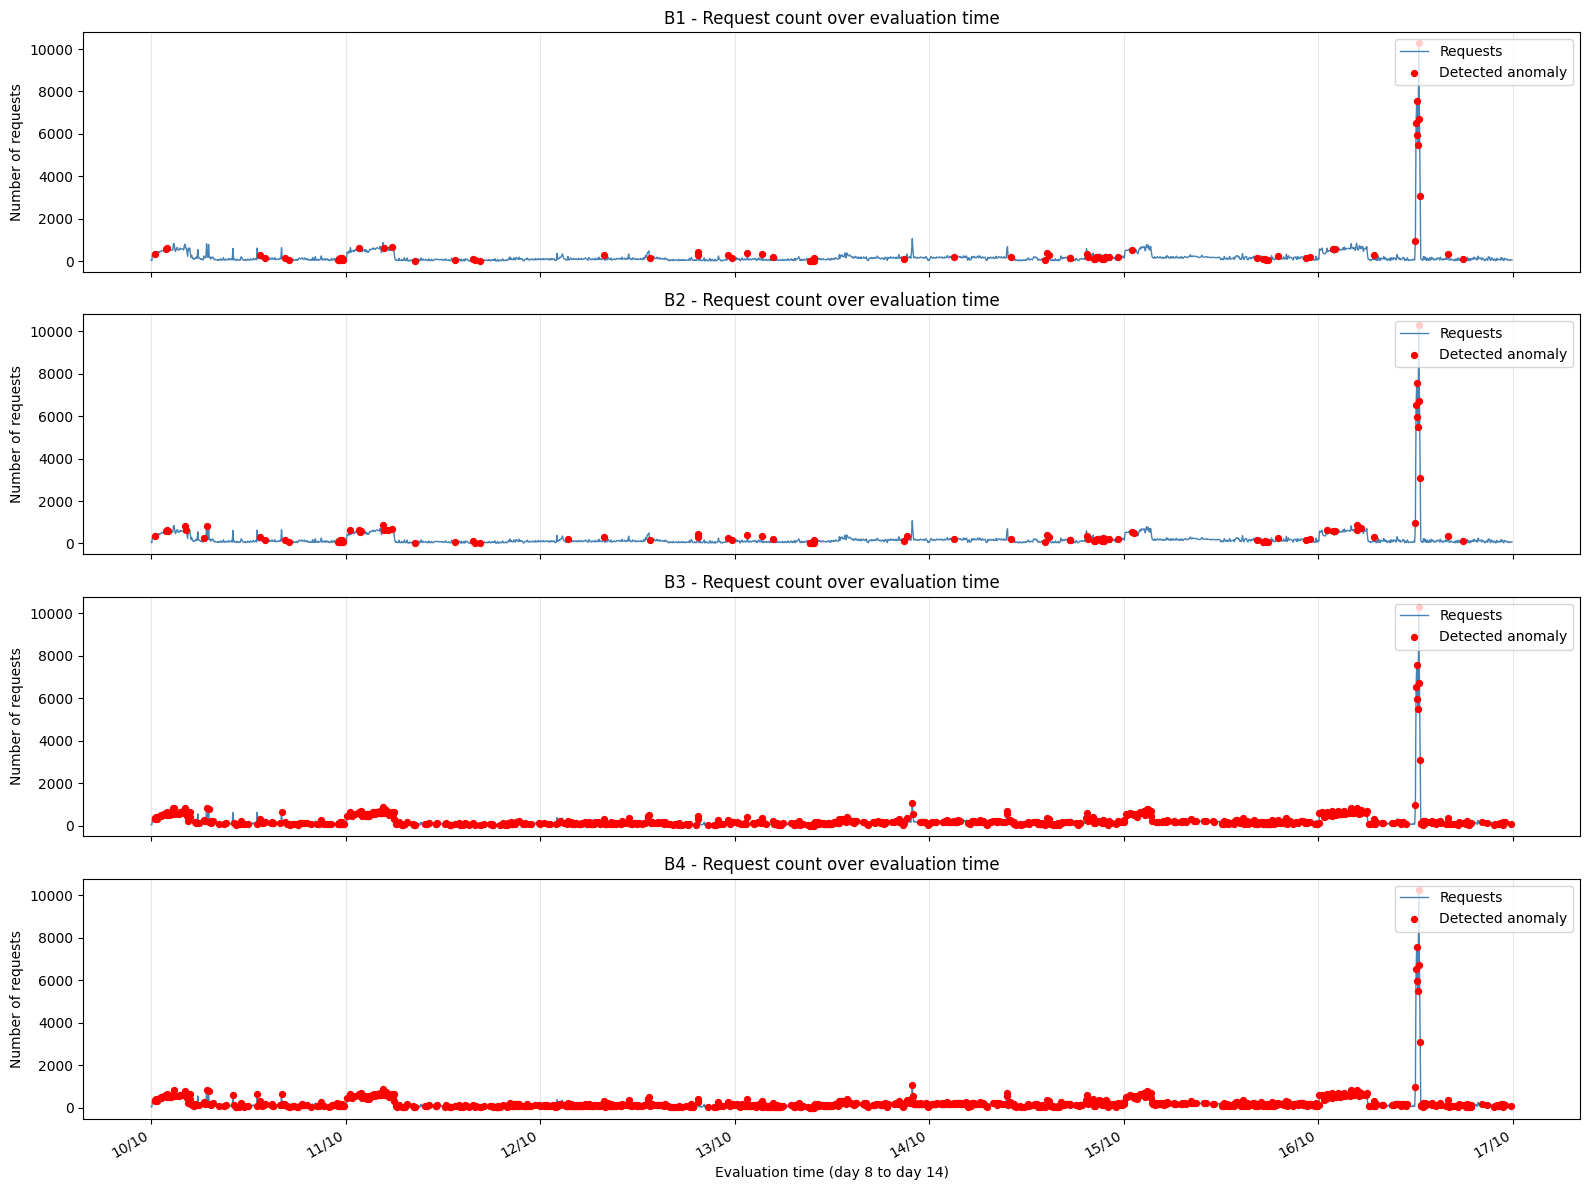

In [32]:
b1_evaluation_predictions = b2_evaluation_df[["timestamp", "request_count"]].merge(
    predictions_df[["timestamp", "is_anomaly"]],
    on="timestamp",
    how="left",
    validate="one_to_one",
)

baseline_request_flags = {
    "B1": b1_evaluation_predictions["is_anomaly"].fillna(False).to_numpy(),
    "B2": flag_matrix.any(axis=1).to_numpy(),
    "B3": b3_flag_matrix.any(axis=1).to_numpy(),
    "B4": b4_flag_matrix.any(axis=1).to_numpy(),
}

fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)
request_timestamps = pd.to_datetime(b2_evaluation_df["timestamp"]).reset_index(drop=True)
request_counts = b2_evaluation_df["request_count"].reset_index(drop=True)

for ax, (baseline_name, anomaly_flags) in zip(axes, baseline_request_flags.items()):
    anomaly_mask = pd.Series(anomaly_flags)
    ax.plot(request_timestamps, request_counts, color="steelblue", linewidth=1, label="Requests")
    flagged = anomaly_mask.to_numpy(dtype=bool)
    ax.scatter(
        request_timestamps[flagged],
        request_counts[flagged],
        color="red",
        s=18,
        label="Detected anomaly",
        zorder=3,
    )
    ax.set_title(f"{baseline_name} - Request count over evaluation time")
    ax.set_ylabel("Number of requests")
    ax.grid(axis="x", alpha=0.3)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Evaluation time (day 8 to day 14)")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In this graph, we can see that B3 and B4 trigger too many alerts simultaneously (exhibiting very similar behavior), whereas B1 and B2 generate fewer alerts over time - though still a significant number for human intervention - and detect nearly the same anomalous points.

## Additional Evaluation Metrics

For each reference, a window is considered "flagged" if at least one of its six features triggers an alert. A sequence of alerts is defined as an uninterrupted series of flagged 5-minute windows; the sequence ends as soon as a non-flagged window occurs. The duration of a sequence is calculated as the number of windows multiplied by 5 minutes. Temporal concentration is presented by UTC date and across four time intervals (00:00–06:00, 06:00–12:00, 12:00–18:00, and 18:00–24:00). Signal coherence is summarized through pairwise co-occurrences.

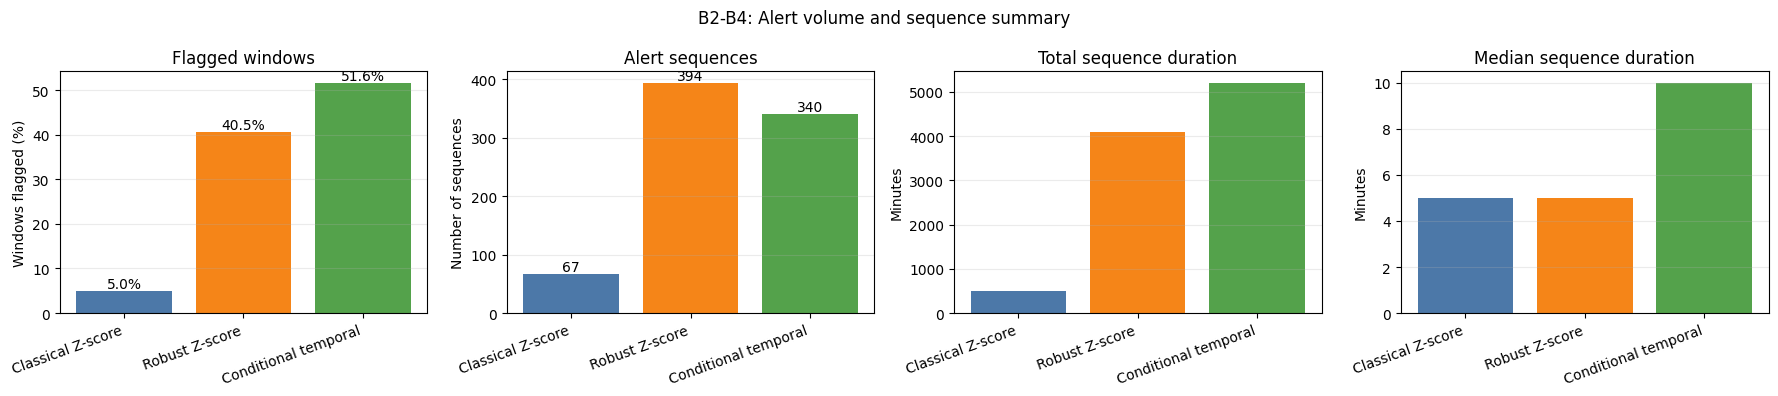

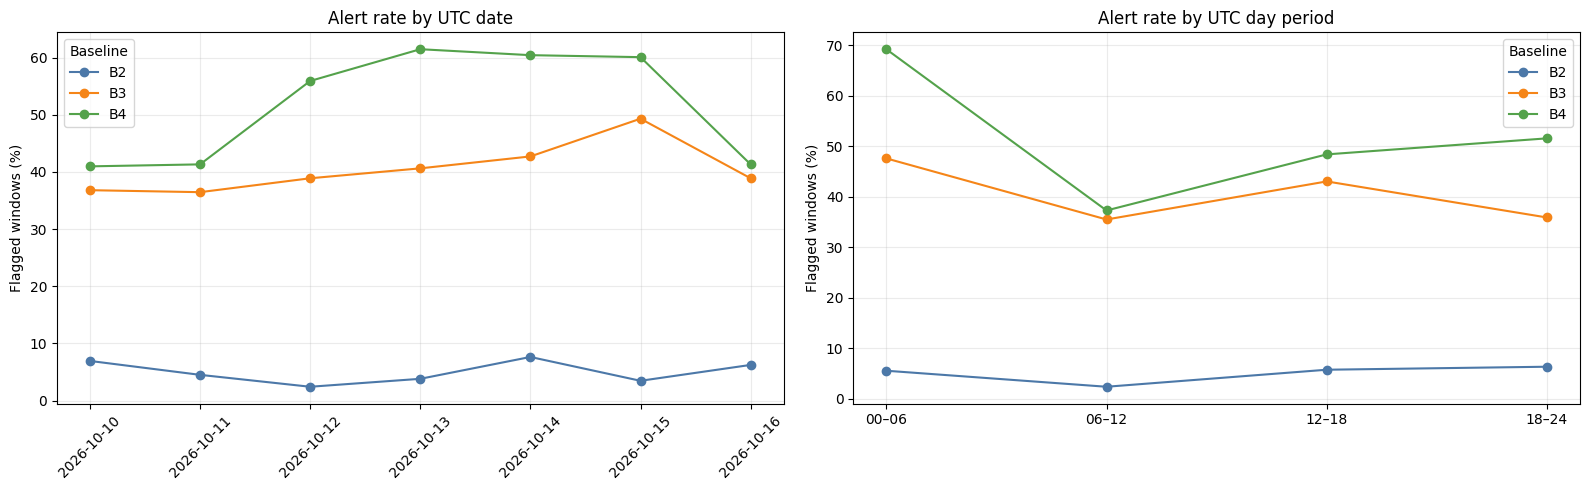

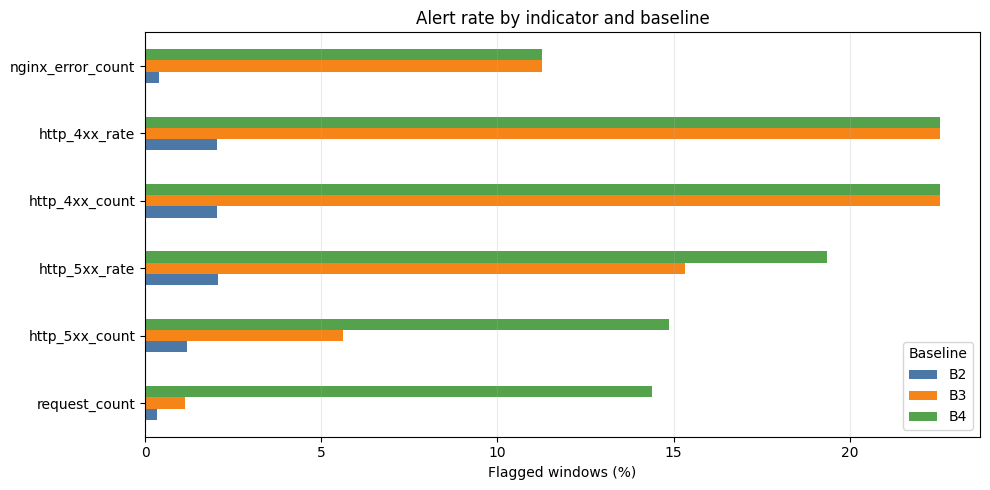

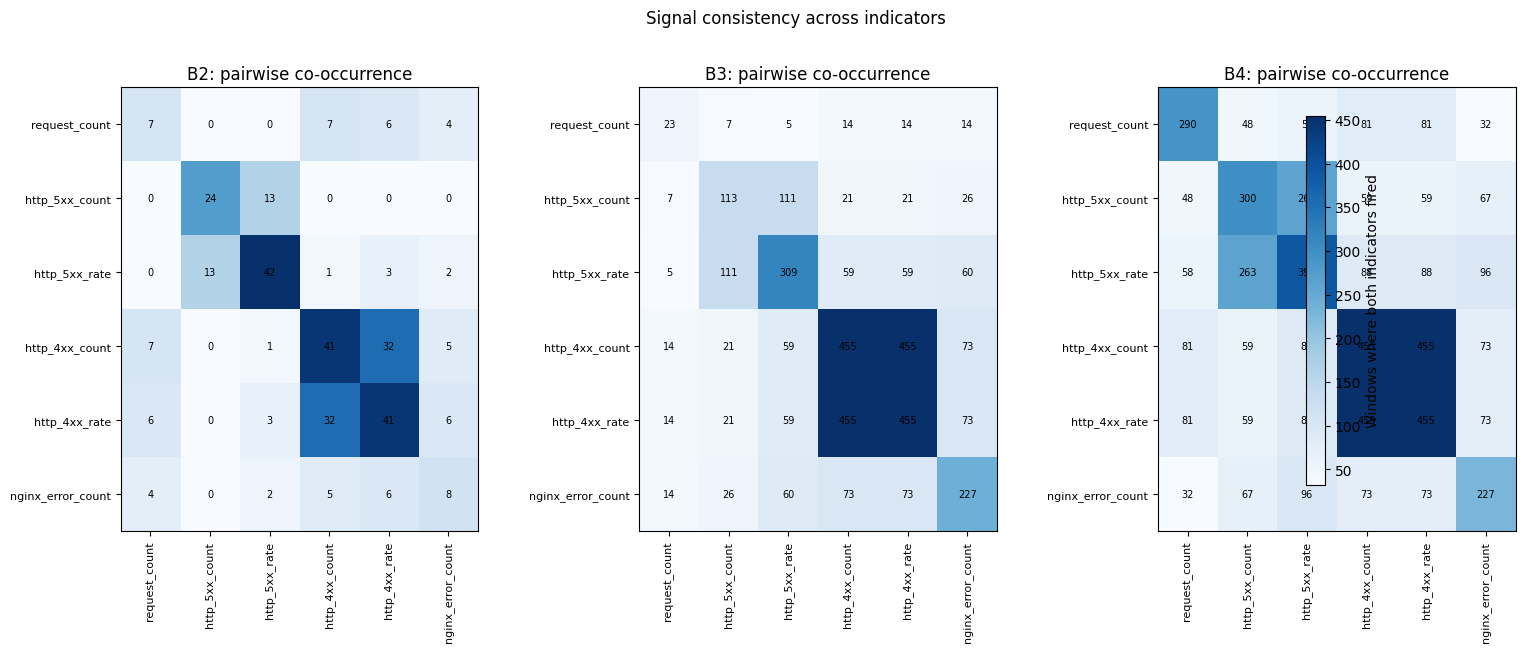

In [33]:

evaluation_reports = {
    "B2": report_evaluation_metrics(flag_matrix),
    "B3": report_evaluation_metrics(b3_flag_matrix),
    "B4": report_evaluation_metrics(b4_flag_matrix),
}

baseline_colors = {"B2": "#4C78A8", "B3": "#F58518", "B4": "#54A24B"}
baseline_names = {"B2": "Classical Z-score", "B3": "Robust Z-score", "B4": "Conditional temporal"}

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for code, report in evaluation_reports.items():
    metrics = report.sequence_metrics
    axes[0].bar(code, metrics["flagged_rate"] * 100, color=baseline_colors[code])
    axes[1].bar(code, metrics["alert_sequences"], color=baseline_colors[code])
    axes[2].bar(code, metrics["total_sequence_duration_minutes"], color=baseline_colors[code])
    axes[3].bar(code, metrics["median_sequence_duration_minutes"], color=baseline_colors[code])
    axes[0].text(code, metrics["flagged_rate"] * 100, f"{metrics['flagged_rate']:.1%}", ha="center", va="bottom")
    axes[1].text(code, metrics["alert_sequences"], str(metrics["alert_sequences"]), ha="center", va="bottom")
axes[0].set_title("Flagged windows")
axes[0].set_ylabel("Windows flagged (%)")
axes[1].set_title("Alert sequences")
axes[1].set_ylabel("Number of sequences")
axes[2].set_title("Total sequence duration")
axes[2].set_ylabel("Minutes")
axes[3].set_title("Median sequence duration")
axes[3].set_ylabel("Minutes")
for ax in axes:
    ax.set_xticks(range(len(baseline_names)), baseline_names.values(), rotation=20, ha="right")
    ax.grid(axis="y", alpha=0.25)
fig.suptitle("B2-B4: Alert volume and sequence summary")
fig.tight_layout()
plt.show()

# Alert concentration by UTC date and time of day.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for code, report in evaluation_reports.items():
    matrix = {
        "B2": flag_matrix,
        "B3": b3_flag_matrix,
        "B4": b4_flag_matrix,
    }[code]
    flagged = matrix.any(axis=1)

    daily = (
        flagged.groupby(flagged.index.floor("D"))
        .mean()
        .to_frame("flagged_rate")
    )

    periods = (
        flagged.groupby(
            pd.cut(
                flagged.index.hour,
                bins=[0, 6, 12, 18, 24],
                labels=["00–06", "06–12", "12–18", "18–24"],
                right=False,
            ),
            observed=False,
        )
        .mean()
        .to_frame("flagged_rate")
    )
    axes[0].plot(daily.index, daily["flagged_rate"] * 100, marker="o", label=code, color=baseline_colors[code])
    # No replacement needed.
    axes[1].plot(periods.index.astype(str), periods["flagged_rate"] * 100, marker="o", label=code, color=baseline_colors[code])
axes[0].set_title("Alert rate by UTC date")
axes[0].set_ylabel("Flagged windows (%)")
axes[0].tick_params(axis="x", rotation=45)
axes[1].set_title("Alert rate by UTC day period")
axes[1].set_ylabel("Flagged windows (%)")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend(title="Baseline")
fig.tight_layout()
plt.show()

# Per-indicator alert rates across baselines.
feature_names = flag_matrix.columns
flag_matrices = {"B2": flag_matrix, "B3": b3_flag_matrix, "B4": b4_flag_matrix}
feature_rates = pd.DataFrame(
    {
        code: matrix[feature_names].fillna(False).astype(bool).mean() * 100
        for code, matrix in flag_matrices.items()
    },
    index=feature_names,
)
fig, ax = plt.subplots(figsize=(10, 5))
feature_rates.plot(kind="barh", ax=ax, color=[baseline_colors[code] for code in feature_rates.columns])
ax.set_title("Alert rate by indicator and baseline")
ax.set_xlabel("Flagged windows (%)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
ax.legend(title="Baseline")
fig.tight_layout()
plt.show()

# Pairwise overlap between feature alerts.
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (code, matrix) in zip(axes, flag_matrices.items()):
    flags = matrix[feature_names].fillna(False).astype("int64")
    overlap = flags.T.dot(flags)
    image = ax.imshow(overlap.to_numpy(), cmap="Blues", aspect="auto")
    ax.set_title(f"{code}: pairwise co-occurrence")
    ax.set_xticks(range(len(overlap.columns)), overlap.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(len(overlap.index)), overlap.index, fontsize=8)
    for row in range(len(overlap.index)):
        for column in range(len(overlap.columns)):
            ax.text(column, row, str(overlap.iat[row, column]), ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=axes, label="Windows where both indicators fired", shrink=0.8)
fig.suptitle("Signal consistency across indicators")
fig.subplots_adjust(top=0.85, wspace=0.45)
plt.show()